In [1]:
from collections import Counter
from collections import defaultdict

# Base
import math
import os
from math import sqrt

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)

# Pattern Mining
from fim import (
    fpgrowth,
    apriori,
)

# Xmeans

from pyclustering.cluster import xmeans

In [2]:
df_primo = pd.read_csv('a_cmi_internet.csv')

df_17 = df_primo[df_primo['Basic_Demos-Age'] <= 17].copy()

df_17= df_17.drop('id', axis=1)

''''FGC-FGC_GSND','FGC-FGC_GSD' sarebbero da non considerare per l'imputazione dei dati mancanti visto che sono presenti tantissimi 
missing values e la maggior parte dei valori sono tutti uguali:

Numero di volte in cui appare ogni valore nella colonna 'FGC-FGC_GSND':
FGC-FGC_GSND
20.05    1387
17.40     401
17.50     383
17.30     282
17.60     198

FGC-FGC_GSD
21.20    1390
18.75    1346
19.00     107
18.50      89
24.75      61
'''

colonna_da_analizzare = 'FGC-FGC_GSND'
colonna_da_analizzare2 = 'FGC-FGC_GSD'

conteggio_valori = df_17[colonna_da_analizzare].value_counts()
conteggio_valori2 = df_17[colonna_da_analizzare2].value_counts()

#print(conteggio_valori)
#print(conteggio_valori2)


'''i valori di 'CGAS-CGAS_Score' hanno un range ufficiale da 1-100 secondo 
https://www.corc.uk.net/outcome-measures-guidance/directory-of-outcome-measures/childrens-global-assessment-scale-cgas/

di conseguenza i valori oltre il 100 sono stati considerati come errori di inserimento e trattati quindi 
come valori mancanti'''

df_17["CGAS-CGAS_Score"] = df_17["CGAS-CGAS_Score"].mask(lambda x: x > 100, np.nan)

df_17['Fitness_Endurance-Tempo_totale']= df_17['Fitness_Endurance-Time_Sec']+(df_17['Fitness_Endurance-Time_Mins']*60)

'''considerando che in queste spcifiche colonne è impossibile che i valori siano pari a 0 (bmi,altezza e così via), gli 
zeri vengono considerati come valori mancanti e imputati. Per quanto riguarda i valori strani ma che non sono
zero, dato che non esiste un range ufficiale come per lo score, vengono trattati come outliers

ci sono degli zero nelle grip strenght che seconod me vanno lasciati ma gli altri li vogliono togliere visto che alcuni hanno 0 in grip ma
ad esempio 20 push up
'''
colonne_zeri=['Physical-BMI', 'Physical-Weight', 'Physical-Diastolic_BP','Physical-Systolic_BP']
df_17[colonne_zeri] =df_17[colonne_zeri] .mask(lambda x: x==0, np.nan)

'''il range di valori va da 1 a 5 quindi i valori sotto l'1 vengono arrotondati (0.66,0.99)'''
df_17['PAQ_A-PAQ_A_Total'] = df_17['PAQ_A-PAQ_A_Total'].clip(lower=1)
df_17['PAQ_C-PAQ_C_Total'] = df_17['PAQ_C-PAQ_C_Total'].clip(lower=1)

train_set, test_set = train_test_split(
    df_17, test_size=0.3, stratify=df_17["sii"], random_state=222)

train_set = train_set.copy()
test_set = test_set.copy()
print(f"\nDimensioni Train Set: {train_set.shape}")
print(f"\nDimensioni Test Set: {test_set.shape}")

train_set = train_set.copy()
test_set = test_set.copy()



Dimensioni Train Set: (5728, 82)

Dimensioni Test Set: (2456, 82)


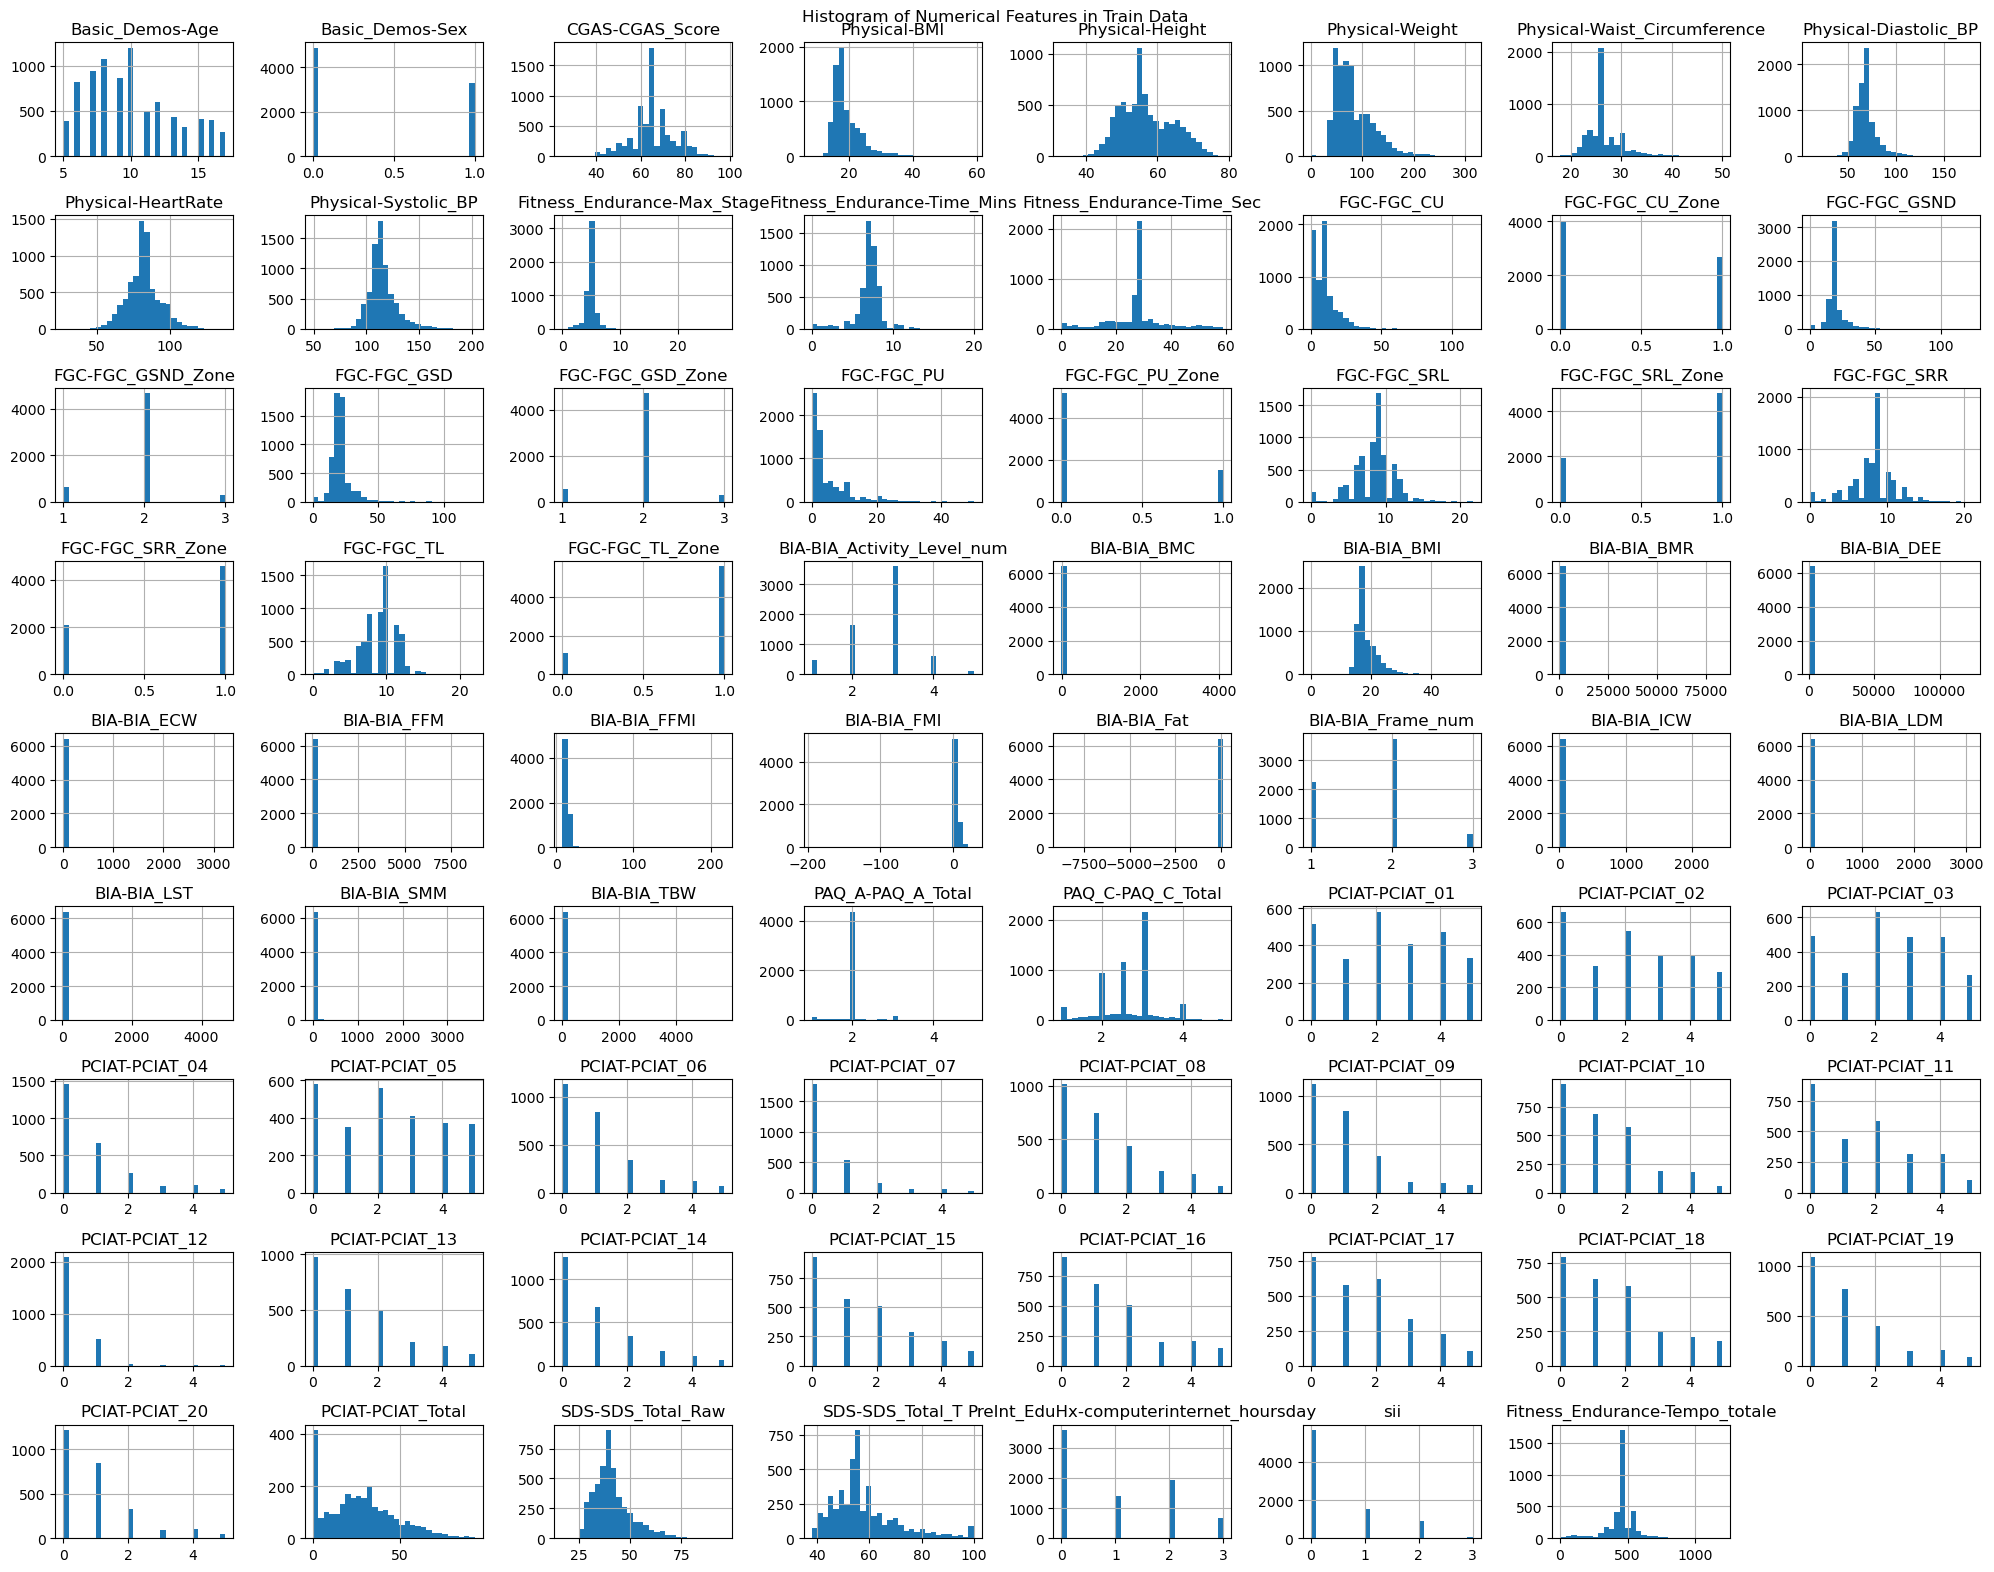

In [3]:
df_17.hist(figsize=(20, 16), bins=30)
plt.suptitle('Histogram of Numerical Features in Train Data')
plt.tight_layout()
plt.show()

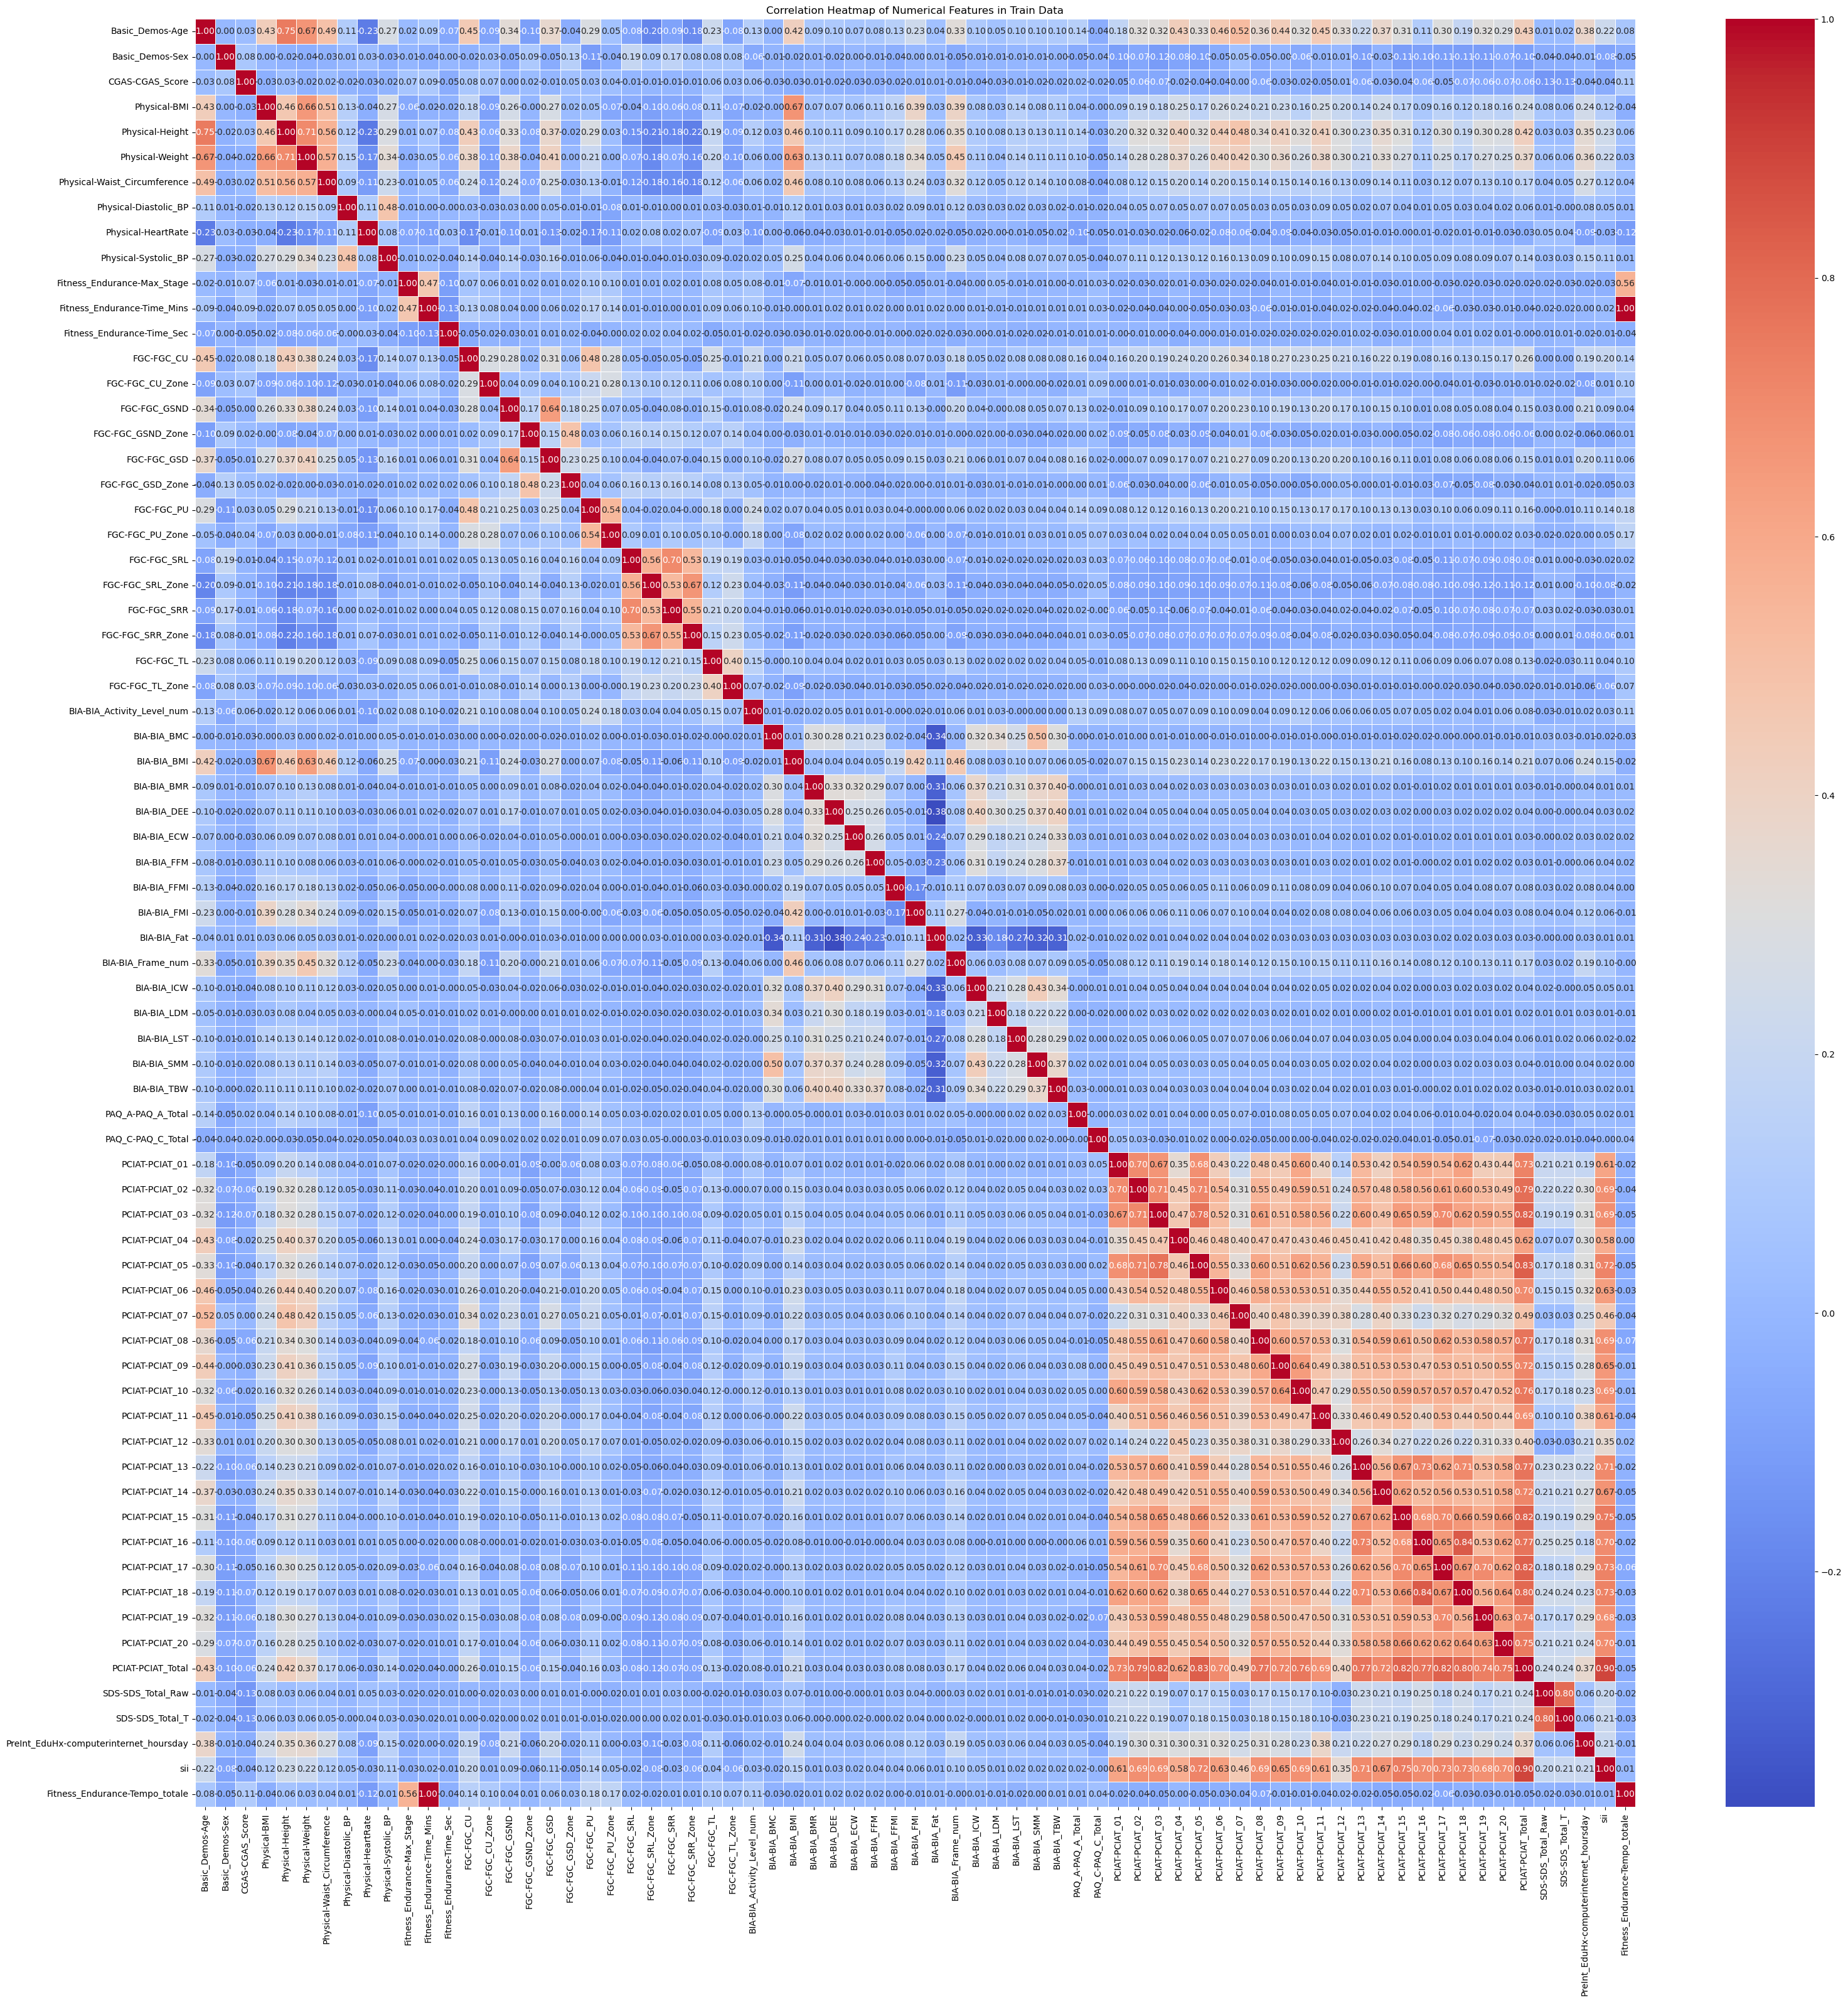

In [4]:
# Select only numerical columns for correlation matrix
numerical_columns = df_17.select_dtypes(include=['float64', 'int64'])

# Compute the correlation matrix
corr = numerical_columns.corr()

# Heatmap of correlation matrix
plt.figure(figsize=(32, 32))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features in Train Data')
plt.tight_layout()
plt.show()

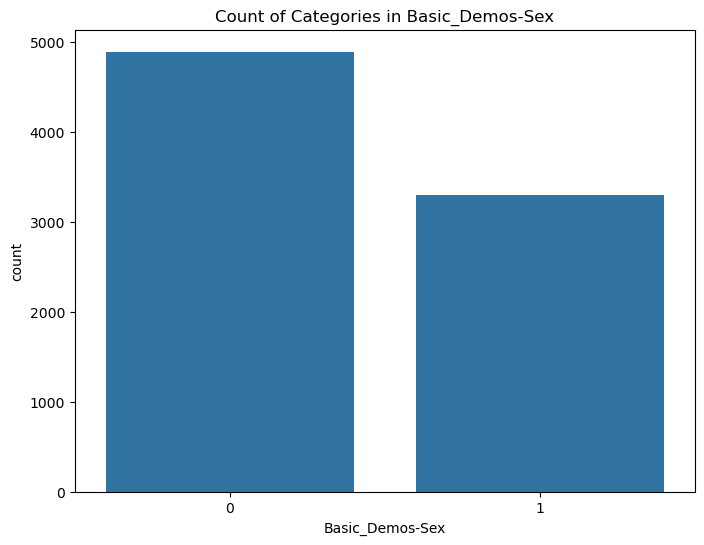

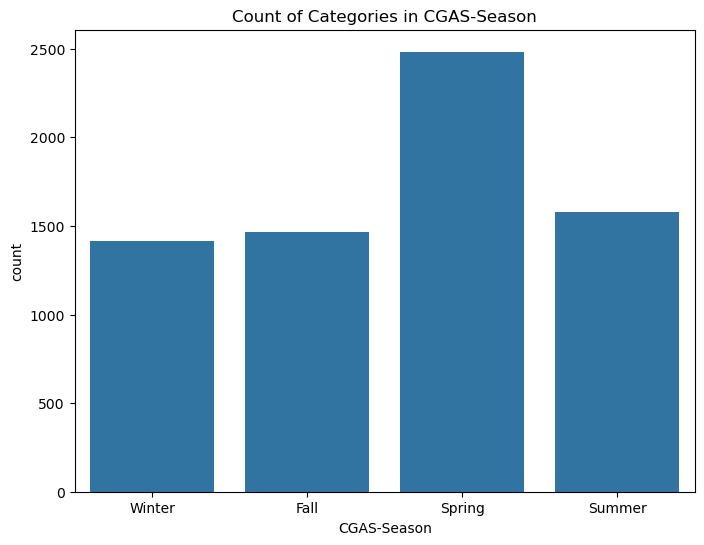

In [5]:
# Plot categorical features (example for 'Basic_Demos-Sex')
plt.figure(figsize=(8, 6))
sns.countplot(x='Basic_Demos-Sex', data=df_17)
plt.title('Count of Categories in Basic_Demos-Sex')
plt.show()

# Example for 'CGAS-Season'
plt.figure(figsize=(8, 6))
sns.countplot(x='CGAS-Season', data=df_17)
plt.title('Count of Categories in CGAS-Season')
plt.show()

In [6]:
#--- IMPUTAZIONE KNN
from tqdm import tqdm

col_quantitative = df_17.select_dtypes(include=["int64", "float64"]).columns

# imputazione

imputer = KNNImputer(n_neighbors=76) #np.sqrt(5823)
train_imputed = pd.DataFrame(
    imputer.fit_transform(train_set[col_quantitative]), 
    columns=col_quantitative, 
    index=train_set.index)

test_imputed = pd.DataFrame(
    imputer.transform(test_set[col_quantitative]), 
    columns=col_quantitative, 
    index=test_set.index
)


In [7]:
from sklearn.ensemble import HistGradientBoostingRegressor

# Molto più veloce di RandomForest
hgb_estimator = HistGradientBoostingRegressor(random_state=222, max_iter=50) 

imputer_rf = IterativeImputer(
    estimator=hgb_estimator, 
    random_state=222, 
    max_iter=5,  # Ridurre le iterazioni a 5 spesso basta per convergere
    tol=1e-2     # Esci prima se i valori non cambiano molto
)

col_da_escludere = [
    "FGC-FGC_CU_Zone", "FGC-FGC_GSND_Zone", "FGC-FGC_GSD_Zone", 
    "FGC-FGC_PU_Zone", "FGC-FGC_SRL_Zone", "FGC-FGC_SRR_Zone", 
    "FGC-FGC_TL_Zone"
]

col_non_bin = col_quantitative.difference(col_da_escludere)

train_imputed_rf = pd.DataFrame(
    imputer_rf.fit_transform(train_set[col_non_bin]), 
    columns=col_non_bin, 
    index=train_set.index
)

test_imputed_rf = pd.DataFrame(
    imputer_rf.transform(test_set[col_non_bin]), 
    columns=col_non_bin, 
    index=test_set.index
)

KeyboardInterrupt: 

In [ ]:
conteggio_val = test_imputed_rf['Fitness_Endurance-Max_Stage'].value_counts()
conteggio_val

Fitness_Endurance-Max_Stage
5.000000    911
4.500000    223
6.000000    137
4.000000    115
5.500000     53
           ... 
4.194444      1
4.885605      1
6.746509      1
4.554504      1
4.913942      1
Name: count, Length: 891, dtype: int64

In [ ]:
sns.set_theme(style="white")

def plot_professional_matrix(corr_matrix, title="Correlation Matrix"):
    # Creazione di una singola figura
    fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)

    # Maschera per nascondere la parte superiore (triangolo)
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    # Palette divergente professionale (es. Rosso-Blu)
    cmap = sns.diverging_palette(230, 20, as_cmap=True)

    # Generazione della heatmap
    sns.heatmap(corr_matrix,
                mask=mask,
                cmap=cmap,
                vmax=1, vmin=-1, center=0,
                square=True,
                linewidths=.5,
                cbar_kws={"shrink": .5},
                annot=False,             # Impostare a True per mostrare i numeri
                fmt=".2f",               # Formato arrotondamento decimali
                ax=ax)

    # Impostazione del titolo
    ax.set_title(title, fontsize=16, pad=20)

    plt.show()

#plot_professional_matrix(correlazione)

NameError: name 'correlazione' is not defined

In [ ]:

colonne_selezionate = ['Physical-BMI', 'Physical-Height', 'Physical-Weight', 'Basic_Demos-Age']

unita_normali = df_17[colonne_selezionate].copy()

unita_normali['altezza_metri'] = unita_normali['Physical-Height'] * 0.0254
unita_normali['peso']= unita_normali['Physical-Weight']*0.453592


In [ ]:
df_17.to_csv('df.csv', index=False, sep=',')
train_set.to_csv('train_set.csv', index=False, sep=',')
test_set.to_csv('test_set.csv', index=False, sep=',')
train_imputed.to_csv('train_imputed.csv', index=False, sep=',')
test_imputed.to_csv('test_imputed.csv', index=False, sep=',')
train_imputed_rf.to_csv('train_imputed_rf.csv', index=False, sep=',')
test_imputed_rf.to_csv('test_imputed_rf.csv', index=False, sep=',')
unita_normali.to_csv('unita_normali.csv',  index=False, sep=',')

%store col_quantitative
%store col_non_bin 

Stored 'col_quantitative' (Index)
Stored 'col_non_bin' (Index)
